# A simple multimodal RAG

We use **Attention Is All You Need**, your existing **pgvector** container, and **Ollama**.

Read the six numbered sections in `rag.py` for the implementation. This notebook calls the same functions as the Streamlit app. Run `uv sync` in a terminal first, then select the `.venv` Python kernel.

## 1. Load the project

The defaults already match `docker-compose.yml`. `.env` can override them. No API key is needed.

In [1]:
from rag import (
    DEFAULT_PDF, LLM_MODEL,
    index_pdf, is_indexed, pdf_id, search, ask,
)

print("PDF:", DEFAULT_PDF.name)
print("Answer model:", LLM_MODEL)

c:\Users\User\Desktop\cats_paws\AI generative course\RAG multimodal agentique\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PDF: attention is all you need.pdf
Answer model: Qwen3:8b


## 2. Look at the PDF text

LlamaIndex returns one document per page. PyMuPDF also extracts figures and tables in `extract_pdf()`.

In [2]:
from llama_index.readers.file import PyMuPDFReader

documents = PyMuPDFReader().load_data(DEFAULT_PDF)
print("Pages:", len(documents))
print(documents[0].text[:1000])

Pages: 11
Attention Is All You Need
Ashish Vaswani∗
Google Brain
avaswani@google.com
Noam Shazeer∗
Google Brain
noam@google.com
Niki Parmar∗
Google Research
nikip@google.com
Jakob Uszkoreit∗
Google Research
usz@google.com
Llion Jones∗
Google Research
llion@google.com
Aidan N. Gomez∗†
University of Toronto
aidan@cs.toronto.edu
Łukasz Kaiser∗
Google Brain
lukaszkaiser@google.com
Illia Polosukhin∗‡
illia.polosukhin@gmail.com
Abstract
The dominant sequence transduction models are based on complex recurrent or
convolutional neural networks that include an encoder and a decoder. The best
performing models also connect the encoder and decoder through an attention
mechanism. We propose a new simple network architecture, the Transformer,
based solely on attention mechanisms, dispensing with recurrence and convolutions
entirely. Experiments on two machine translation tasks show these models to
be superior in quality while being more parallelizable and requiring signiﬁcantly
less time to train. O

## 3. Index the PDF once

`index_pdf()` extracts text, figures and table regions. We use figure captions already present in the PDF; no image-captioning model is needed. MiniLM creates text embeddings and CLIP creates image embeddings. LlamaIndex saves both in pgvector, in separate tables because their dimensions differ. This first step can take several minutes.

Screenshots preserve the original layout of tables. CLIP creates image embeddings, not written descriptions.

In [3]:
if is_indexed(DEFAULT_PDF):
    print("Already indexed. The database survives app and notebook restarts.")
else:
    counts = index_pdf(DEFAULT_PDF)
    print(counts)

# To deliberately rebuild after changing the extraction code:
# counts = index_pdf(DEFAULT_PDF)

Already indexed. The database survives app and notebook restarts.


## 4. Retrieve text without asking the LLM

The question is embedded with the same model used for document text. pgvector returns nearby vectors. Every result keeps its page number.

In [4]:
document_id = pdf_id(DEFAULT_PDF)
hits = search("What is multi-head attention?", document_id, kind="text")

for hit in hits:
    print("Page", hit.metadata["page"])
    print(hit.text)
    print()

2026-10-24 11:28:49,212 - INFO - Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.


Page 5
MultiHead(Q, K, V ) = Concat(head1, ..., headh)W O
where headi = Attention(QW Q
i , KW K
i , V W V
i )
Where the projections are parameter matrices W Q
i
∈Rdmodel×dk, W K
i
∈Rdmodel×dk, W V
i
∈Rdmodel×dv
and W O ∈Rhdv×dmodel.
In this work we employ h = 8 parallel attention layers, or heads. For each of these we use
dk = dv = dmodel/h = 64. Due to the reduced dimension of each head, the total computational cost
is similar to that of single-head attention with full dimensionality.
3.2.3
Applications of Attention in our Model
The Transformer uses multi-head attention in three different ways:
• In "encoder-decoder attention" layers, the queries come from the previous decoder layer,
and the memory keys and values come from the output of the encoder.

Page 4
On each of these projected versions of
queries, keys and values we then perform the attention function in parallel, yielding dv-dimensional
output values. These are concatenated and once again projected, resulting in the ﬁnal valu

## 5. Retrieve figures and tables

Image search combines CLIP similarity with a search of PDF figure captions. Table search retrieves the original table text. Screenshots stay on disk in `artifacts/`.

c:\Users\User\Desktop\cats_paws\AI generative course\RAG multimodal agentique\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Page 3 Figure 1: The Transformer - model architecture.


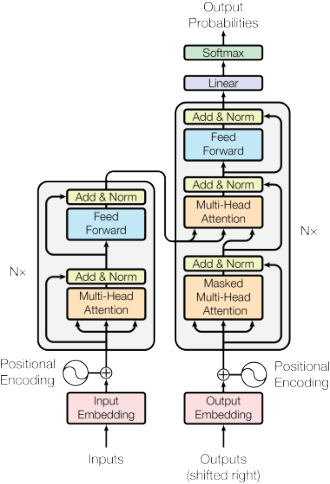

In [5]:
from IPython.display import display, Image

figures = search("Transformer encoder decoder architecture Figure 1", document_id, kind="image")
for figure in figures[:1]:
    print("Page", figure.metadata["page"], figure.text)
    display(Image(filename=figure.metadata["image_path"], width=500))

Page 8
Table 2: The Transformer achieves better BLEU scores than previous state-of-the-art models on the
English-to-German and English-to-French newstest2014 tests at a fraction of the training cost.
                           BLEU           Training Cost (FLOPs)
Model
                         EN-DE  EN-FR     EN-DE    EN-FR
ByteNet [15]                       23.75
Deep-Att + PosUnk [32]                       39.2                   1.0 · 1020
GNMT + RL [31]                    24.6     39.92      2.3 · 1019   1.4 · 1020
ConvS2S [8]                       25.16    40.46      9.6 · 1018   1.5 · 1020
MoE [26]                          26.03    40.56      2.0 · 1019   1.2 · 1020
Deep-Att + PosUnk Ensemble [32]              40.4                   8.0 · 1020
GNMT + RL Ensemble [31]         26.30    41.16      1.8 · 1020   1.1 · 1021
ConvS2S Ensemble [8]              26.36    41.29      7.7 · 1019   1.2 · 1021
Transformer (base model)             27.3     38.1           3.3 · 1018
Transformer (b

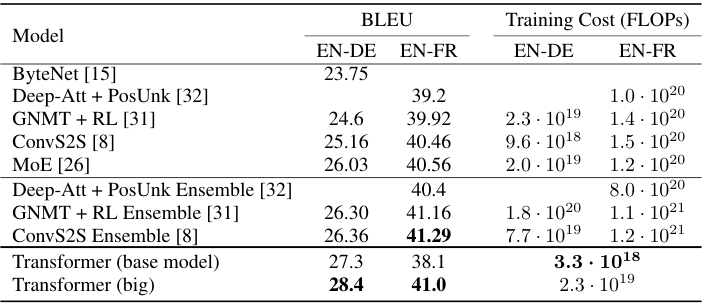

In [6]:
tables = search("Table 2 Transformer base big BLEU scores", document_id, kind="table")
for table in tables[:1]:
    print("Page", table.metadata["page"])
    print(table.text)
    display(Image(filename=table.metadata["image_path"], width=700))

## 6. Ask the LangChain agent

We provide an initial text search. Qwen can call `search_text`, `search_images`, or `search_tables`, then answers from the retrieved sources with citations. `tool_calls` shows its search steps. Each question is independent.

In [7]:
result = ask("Compare the Transformer base and big BLEU scores in Table 2.", DEFAULT_PDF)
from IPython.display import Markdown, display
display(Markdown(result["answer"]))
print("\nSearch steps:")
for step in result["tool_calls"]:
    print(step)

2026-10-24 11:29:07,931 - INFO - HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-24 11:29:09,109 - INFO - HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


The Transformer base model achieved a BLEU score of 27.3 on the English-to-German (EN-DE) task, while the Transformer big model achieved a higher BLEU score of 28.4 on the same task [S4].

Search steps:
{'tool': 'search_text', 'query': 'Compare the Transformer base and big BLEU scores in Table 2.'}
{'tool': 'search_table', 'query': 'Compare the Transformer base and big BLEU scores in Table 2'}


In [8]:
for source in result["sources"]:
    print(f"[{source['id']}] {source['file']}, page {source['page']}, {source['kind']}")
    print()

[S1] attention is all you need.pdf, page 8, text
Table 2: The Transformer achieves better BLEU scores than previous state-of-the-art models on the
English-to-German and English-to-French newstest2014 tests at a fraction of the training cost.
Model
BLEU
Training Cost (FLOPs)
EN-DE
EN-FR
EN-DE
EN-FR
ByteNet [15]
23.75
Deep-Att + PosUnk [32]
39.2
1.0 · 1020
GNMT + RL [31]
24.6
39.92
2.3 · 1019
1.4 · 1020
ConvS2S [8]
25.16
40.46
9.6 · 1018
1.5 · 102

[S2] attention is all you need.pdf, page 9, text
Table 3: Variations on the Transformer architecture. Unlisted values are identical to those of the base
model. All metrics are on the English-to-German translation development set, newstest2013. Listed
perplexities are per-wordpiece, according to our byte-pair encoding, and should not be compared to
per-word perplexities.
N
dmodel
dff
h
dk
dv
Pdrop
ϵls
train
PPL
BLEU
params
steps
(dev)
(dev)
×106


[S3] attention is all you need.pdf, page 8, text
1 [30]. This
hurts perplexity, as the model learn

## Streamlit interface

Run this in a terminal from the project folder:

```powershell
uv run streamlit run main.py
```

Keep the default paper or upload another PDF, index it, and ask your questions. See `README.md` for setup and limitations.